### Odor Pleasantness Rating Analysis

This script analyzes how subjects’ ratings of odor pleasantness change before and after eating a meal, with comparisons across different odor types.

- Odor pleasantness was rated using a horizontal slider, with the cursor starting at the midpoint (0).
- The rating scale ranged from –4 (very unpleasant) to +4 (very pleasant).
- Each odor was rated three times, and the average rating was used for analysis.


We did not collect odor-pleasantness ratings from **sub-36** due to an operational error.  
Additionally, we excluded **sub-19** and **sub-33** to maintain consistency with the participant exclusions applied in the other analyses.

So only 31 subjects are included in this analysis.



In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.stats import wilcoxon
import numpy as np

In [16]:
# load common plot configurations
from plot_config import session_colors

In [17]:
# Base directory
base_path = Path('/Users/liuq13/project-SPCD/beh_processed_subs/')

In [18]:
# Load all subject summaries
all_data = []

for sub_dir in base_path.glob('sub-*'):
    summary_file = sub_dir / 'pleasantness_summary.csv'
    if summary_file.exists():
        df = pd.read_csv(summary_file)
        df['subject'] = sub_dir.name
        all_data.append(df)

# Combine
combined_df = pd.concat(all_data, ignore_index=True)
EXCLUDE_SUBJECTS = ['sub-19', 'sub-33']
combined_df = combined_df[~combined_df['subject'].isin(EXCLUDE_SUBJECTS)]

In [19]:
combined_df

,odor_num,pre_mean,post_mean,change,subject
0,0,0.500,0.125,-0.375,sub-13
1,1,-1.000,-1.250,-0.250,sub-13
2,2,1.750,0.500,-1.250,sub-13
3,0,3.000,3.000,0.000,sub-14
4,2,2.500,2.500,0.000,sub-14
...,...,...,...,...,...
94,1,2.250,1.500,-0.750,sub-32
95,2,2.250,0.500,-1.750,sub-32
96,0,3.000,3.000,0.000,sub-35
97,1,-2.375,-2.750,-0.375,sub-35


In [29]:
# assume combined_df already exists
df = combined_df.copy()

df['odor_num'] = pd.Categorical(df['odor_num'], categories=[2, 1, 0], ordered=True)

df.head()

,odor_num,pre_mean,post_mean,change,subject
0,0,0.50,0.125,-0.375,sub-13
1,1,-1.00,-1.250,-0.250,sub-13
2,2,1.75,0.500,-1.250,sub-13
3,0,3.00,3.000,0.000,sub-14
4,2,2.50,2.500,0.000,sub-14


In [30]:
# --- compute summary stats ---
group_stats = df.groupby("odor_num")["change"].agg(['mean', 'sem']).reset_index()
group_stats

/var/folders/br/nr4k1vxj1_j7jxk17x7xr8n9g2q0k8/T/ipykernel_73587/2848236648.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group_stats = df.groupby("odor_num")["change"].agg(['mean', 'sem']).reset_index()


,odor_num,mean,sem
0,2,-0.935484,0.201962
1,1,-0.108871,0.116476
2,0,0.137097,0.090056


/var/folders/br/nr4k1vxj1_j7jxk17x7xr8n9g2q0k8/T/ipykernel_73587/2344137573.py:15: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("odor_num")["change"]


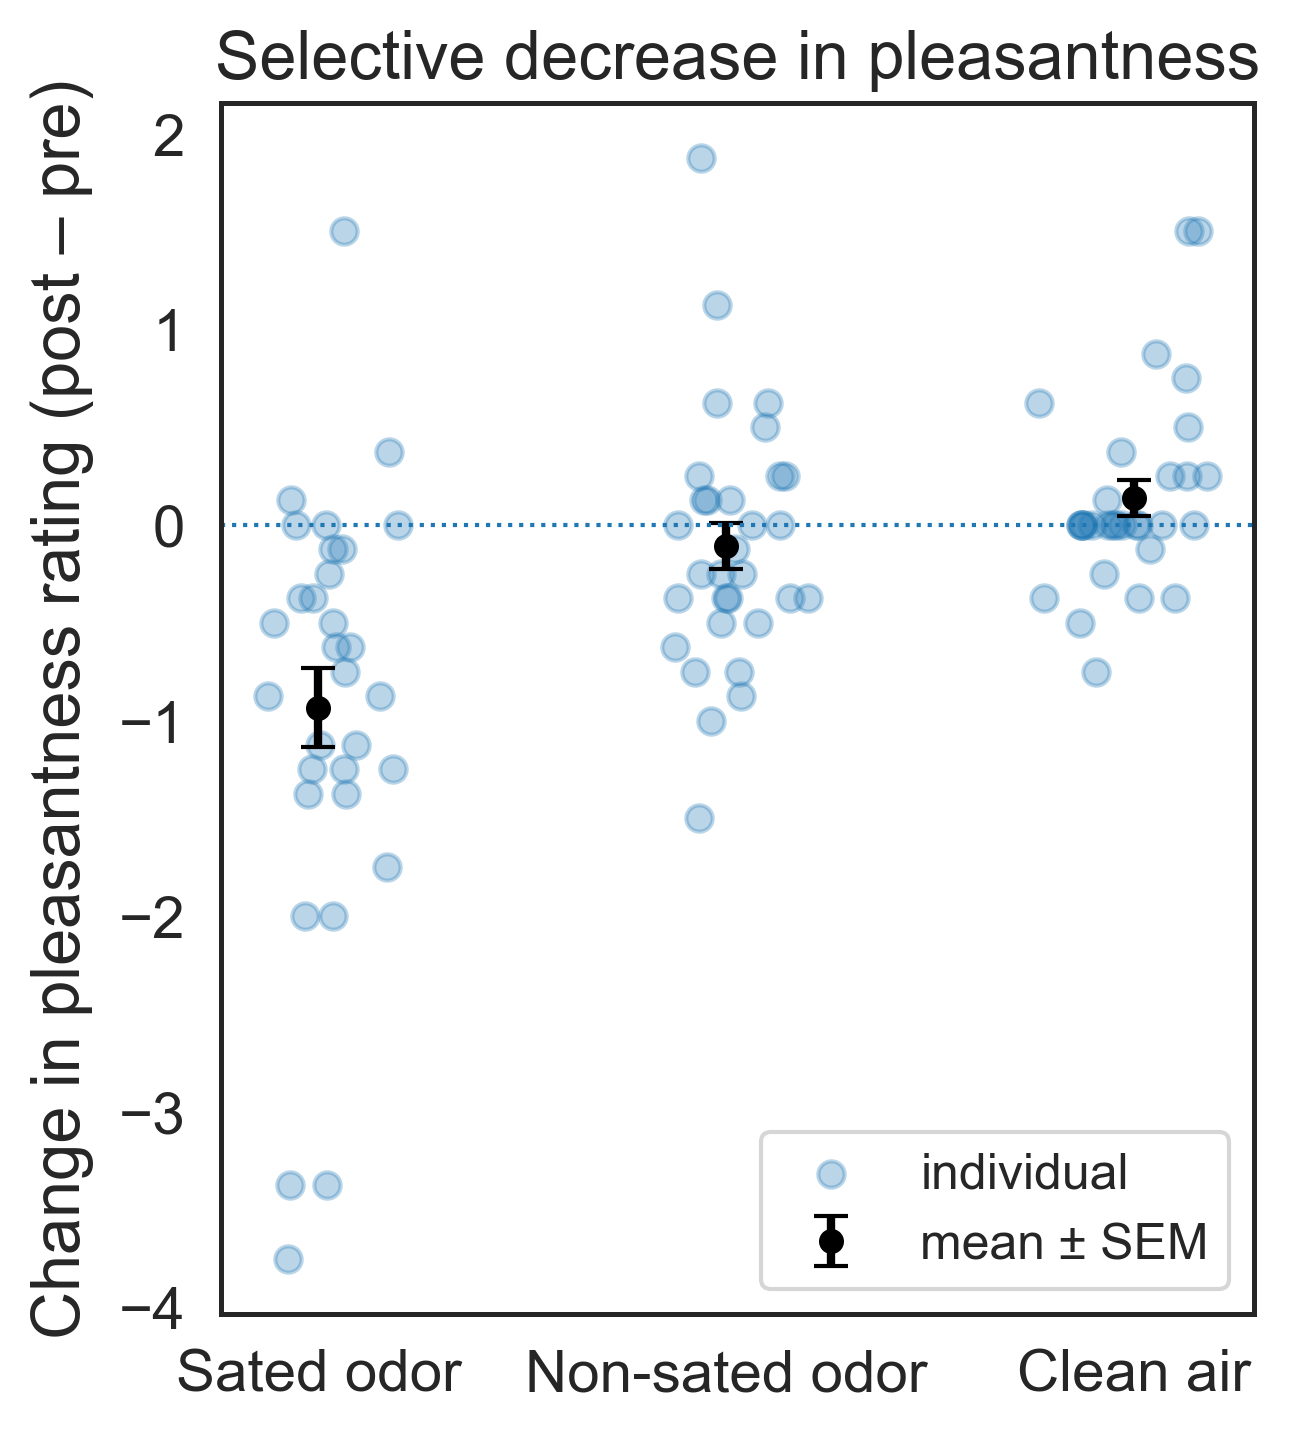

In [32]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# desired order on the x-axis
odor_order = [2, 1, 0]

# make odor_num an ordered categorical
df["odor_num"] = pd.Categorical(df["odor_num"],
                                categories=odor_order,
                                ordered=True)

# --- recompute group stats so they inherit the categorical order ---
group_stats = (
    df.groupby("odor_num")["change"]
      .agg(mean="mean",
           sem=lambda x: x.std(ddof=1) / np.sqrt(len(x)))
      .reset_index()
)

# numeric x-positions from categorical codes (0,1,2 for 2,1,0)
x_points = df["odor_num"].cat.codes
x_centers = group_stats["odor_num"].cat.codes

# --- plotting ---
fig, ax = plt.subplots(figsize=(4.5, 5))

rng = np.random.default_rng(0)
x_jitter = rng.normal(0, 0.1, size=len(df))

# individual dots
ax.scatter(
    x_points + x_jitter,
    df["change"],
    alpha=0.3,
    s=40,
    label="individual"
)

# mean ± SEM
ax.errorbar(
    x_centers,
    group_stats["mean"],
    yerr=group_stats["sem"],
    fmt='o',
    markersize=5,
    capsize=4,
    linewidth=2,
    color='black',
    label="mean ± SEM"
)

ax.axhline(0, linestyle='dotted', linewidth=1)
ax.set_xlabel("")
ax.set_ylabel("Change in pleasantness rating (post – pre)")
ax.set_title("Selective decrease in pleasantness")
ax.legend(frameon=True)

odor_labels = {2: 'Sated odor', 1: 'Non-sated odor', 0: 'Clean air'}
plt.xticks(
    ticks=np.arange(len(odor_order)),
    labels=[odor_labels[o] for o in odor_order]
)

plt.tight_layout()
plt.savefig('../plots/pleasantness_ratings_change.pdf',
            format='pdf', bbox_inches='tight')
plt.show()


In [8]:
from scipy.stats import wilcoxon

# === Perform paired t-tests with detailed stats ===
results = []

for odor in sorted(combined_df['odor_num'].unique()):
    df_odor = combined_df[combined_df['odor_num'] == odor]
    
    pre = df_odor['pre_mean']
    post = df_odor['post_mean']
    n = len(pre)
    
    # Wilcoxon signed-rank test
    stat, pval = wilcoxon(pre, post, alternative='two-sided')
    
    # descriptive stats
    diff = post - pre
    mean_pre = pre.mean()
    mean_post = post.mean()
    mean_diff = diff.mean()
    
    results.append({
        'odor_num': odor,
        'n': n,
        'stat': stat,
        'pval': pval,
        'pre_mean': mean_pre,
        'post_mean': mean_post,
        'mean_diff': mean_diff
    })

# Merge into DataFrame
stat_df = pd.DataFrame(results)
stat_df


,odor_num,n,stat,pval,pre_mean,post_mean,mean_diff
0,0,31,57.5,0.221370,0.774194,0.911290,0.137097
1,1,31,141.0,0.157002,0.895161,0.786290,-0.108871
2,2,31,30.0,0.000081,1.754032,0.818548,-0.935484


In [9]:
# Melt for plotting
melted = pd.melt(
    combined_df,
    id_vars=['subject', 'odor_num'],
    value_vars=['pre_mean', 'post_mean'],
    var_name='session',
    value_name='pleasantness'
)
melted['session'] = melted['session'].str.replace('_mean', '', regex=False)

### plot the mean and error bars

In [10]:
session_labels = {
    'pre': 'pre-meal',
    'post': 'post-meal'
}

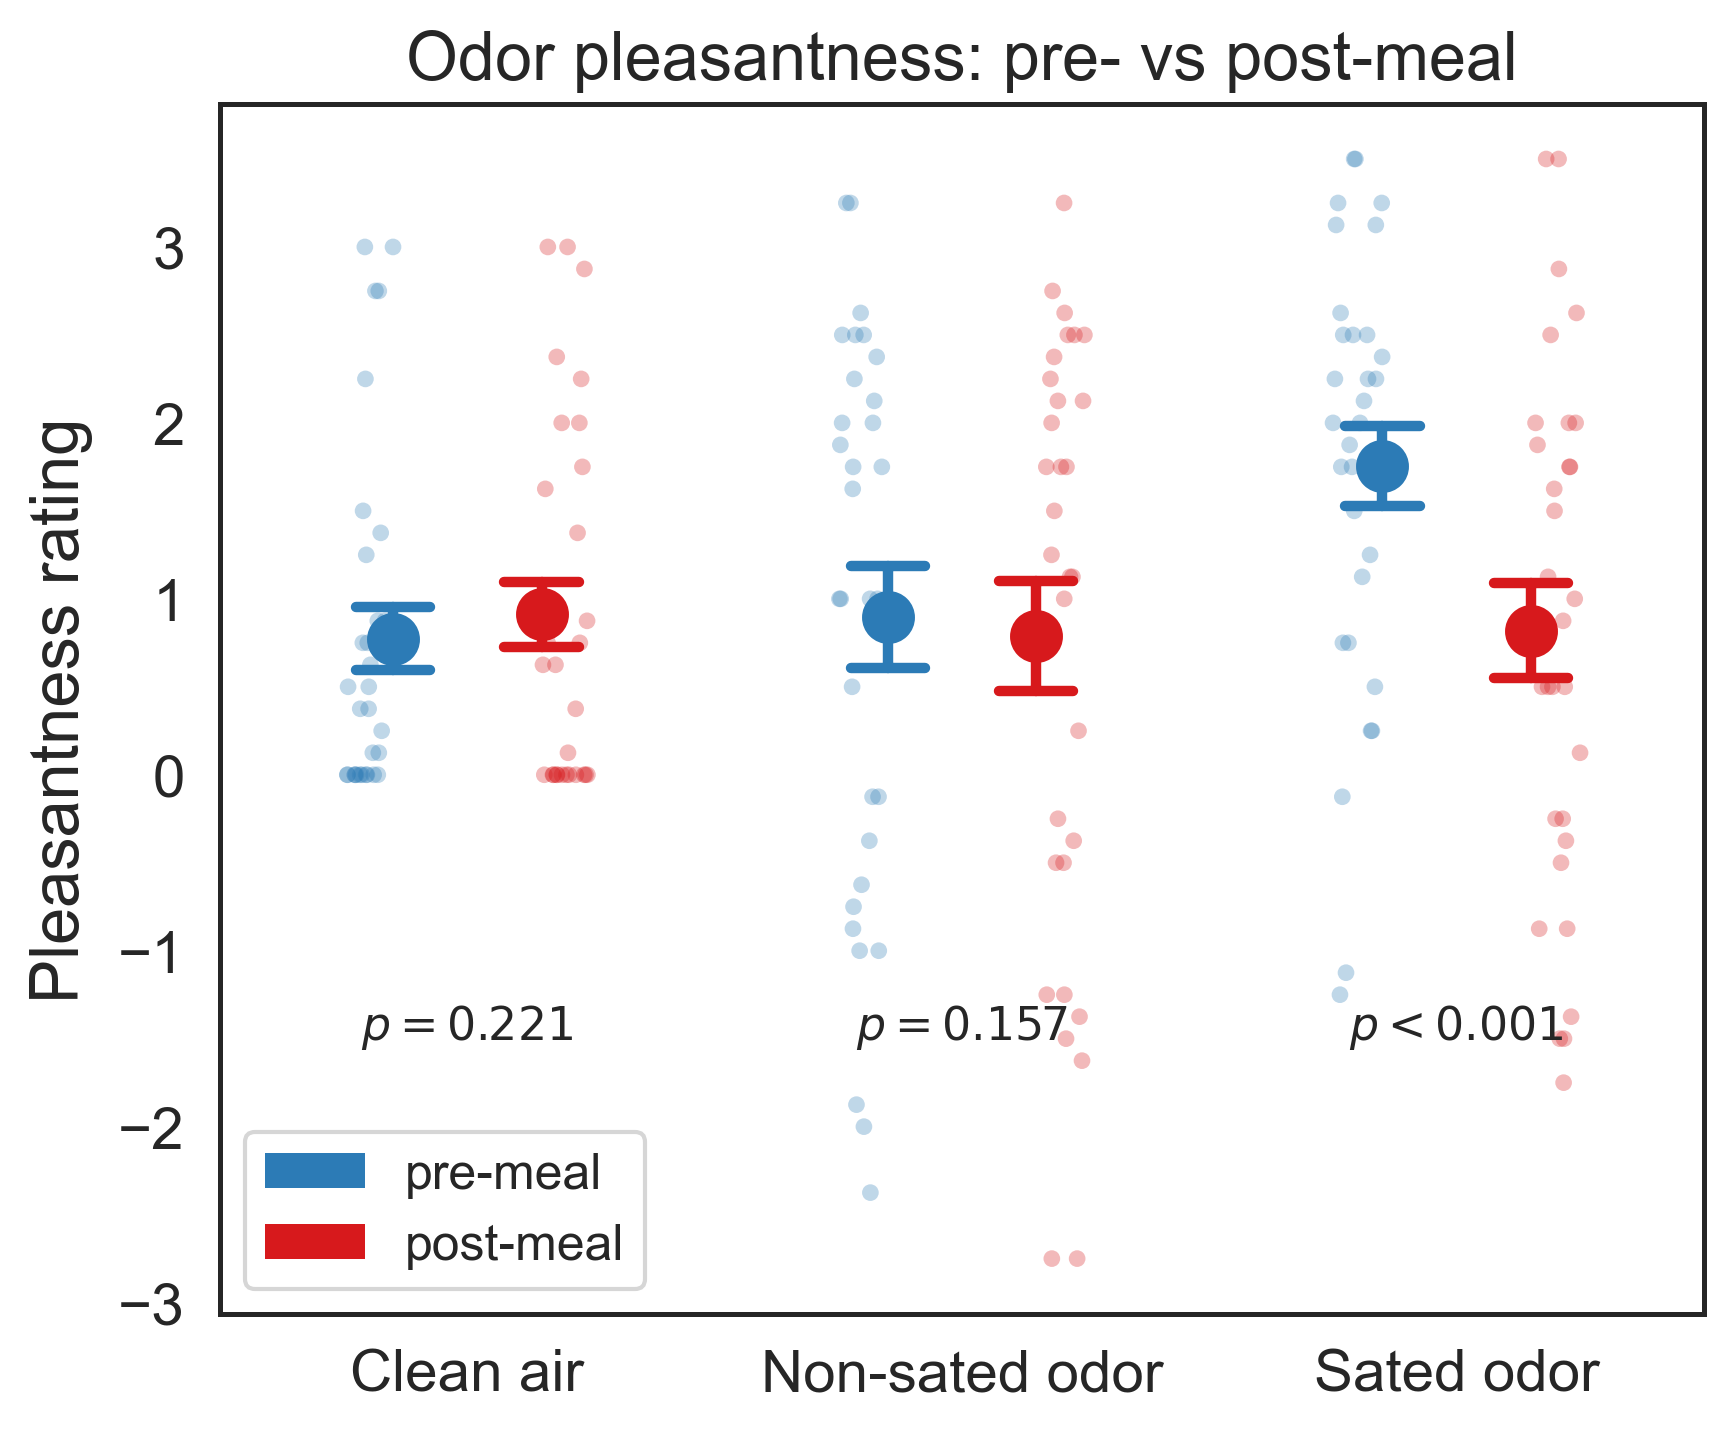

In [13]:
plt.figure(figsize=(6, 5))

# First: individual data points (in the background)
sns.stripplot(
    data=melted, x='odor_num', y='pleasantness', hue='session',
    dodge=True, jitter=True, alpha=0.3, size=4, linewidth=0, edgecolor=None,
    palette=session_colors
)

# Then: mean ± SE, larger and on top
sns.pointplot(
    data=melted, x='odor_num', y='pleasantness', hue='session',
    dodge=0.3, capsize=0.15, errorbar='se', markers='o', 
    err_kws={'linewidth': 2.5}, markersize=10, linestyle='none',
    palette=session_colors
)


# Get current legend handles and labels
handles, labels = plt.gca().get_legend_handles_labels()

# Map 'pre'/'post' to nicer labels
new_labels = [session_labels[label] for label in labels[:2]]

from matplotlib.patches import Patch

# Define custom legend handles using clean patches
legend_handles = [
    Patch(facecolor=session_colors['pre'], edgecolor='none', label='pre-meal'),
    Patch(facecolor=session_colors['post'], edgecolor='none', label='post-meal')
]

# Add legend inside the panel
plt.legend(
    handles=legend_handles,
    loc='lower left',
    frameon=True
)

# Add p-value annotations
for i, row in stat_df.iterrows():
    x = i
    y = -1.5
    pval = row['pval']
    label = f"$p = {pval:.3f}$" if pval >= 0.001 else "$p < 0.001$"
    plt.text(x, y, label, ha='center', fontsize=11, style='italic')

plt.title('Odor pleasantness: pre- vs post-meal')
plt.xlabel('')
plt.ylabel('Pleasantness rating')
odor_labels = {
    0: 'Clean air',
    1: 'Non-sated odor',
    2: 'Sated odor'
}
plt.xticks(ticks=[0, 1, 2], labels=[odor_labels[i] for i in [0, 1, 2]])
plt.tight_layout()
plt.savefig('../plots/pleasantness_ratings.pdf', format='pdf', bbox_inches='tight')
plt.show()


### Summary of Results

The boxplot compares pleasantness ratings for three types of odors — **Clean Air**, **Non-devalued Odor**, and **Devalued Odor** — before and after a meal. 

- **Clean Air**: No significant change in pleasantness rating   
- **Non-devalued Odor**: No significant change
- **Devalued Odor**: Significant decrease in pleasantness rating

These results indicate a specific devaluation effect, where the odor associated with the consumed food becomes less pleasant after eating.
